# BÀI THỰC HÀNH 3.2: K-MEANS IMAGE SEGMENTATION
## NOTEBOOK 02: K-MEANS TỰ LẬP TRÌNH VÀ THEO DÕI TIẾN TRÌNH HỘI TỤ (TASK 3)

Nội dung trọng tâm:
- Hiện thực hóa đúng 4 bước thuật toán K-Means theo đề bài bằng thư viện NumPy:
  1. **Initialize**: Khởi tạo $K$ tâm cụm ngẫu nhiên không trùng lặp.
  2. **Assign**: Gán mỗi pixel vào tâm gần nhất theo khoảng cách Euclidean bình phương.
  3. **Update**: Cập nhật lại tâm cụm bằng trung bình cộng các pixel trong cụm (xử lý an toàn cụm rỗng).
  4. **Repeat**: Lặp lại tới khi độ dịch chuyển tâm $\le tol$ hoặc đạt `max_iter`.
- Theo dõi chi tiết diễn biến quán tính WCSS, độ dịch chuyển tâm và tỷ lệ đổi nhãn qua từng vòng lặp.

### 1. Nạp các thư viện và chuẩn bị ma trận điểm ảnh

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import DEFAULT_IMAGE_PATH, TARGET_SIZE, RANDOM_SEED, FIGURES_DIR
from src.data.loader import load_image
from src.data.preprocessing import resize_image, flatten_pixels
from src.models.kmeans_scratch import KMeansFromScratch
from src.evaluation.visualization import plot_convergence_tracking

# Nạp và tiền xử lý ảnh để lấy ma trận pixel
img_rgb, metadata = load_image(DEFAULT_IMAGE_PATH)
img_resized, (h_resized, w_resized) = resize_image(img_rgb, target_size=TARGET_SIZE)
pixel_matrix = flatten_pixels(img_resized, as_float=True)

print(f"Đã nạp ma trận pixel thành công: {pixel_matrix.shape}")

2026-11-14 11:08:41 [INFO] DataLoader — Đọc ảnh bằng OpenCV: image-liquid.jpg
2026-11-14 11:08:41 [INFO] DataLoader — Ảnh đã nạp — image-liquid.jpg | 3264×3264×3 | 10,653,696 pixels | 2095.2 KB
2026-11-14 11:08:41 [INFO] Preprocessing — Resize ảnh: (3264x3264) -> (256x256) | scale=0.078
2026-11-14 11:08:41 [INFO] Preprocessing — Flatten pixels: (256x256x3) -> (65536, 3) | dtype=float32
Đã nạp ma trận pixel thành công: (65536, 3)


### 2. Huấn luyện mô hình K-Means from Scratch (Baseline K=4)
Khởi tạo đối tượng `KMeansFromScratch` với $K=4$, số vòng tối đa 50 và kiểm soát seed ngẫu nhiên.

In [2]:
K_CLUSTERS = 4

model_scratch = KMeansFromScratch(
    n_clusters=K_CLUSTERS,
    max_iter=50,
    tol=1e-4,
    random_state=RANDOM_SEED
)

print(f"=== BẮT ĐẦU HUẤN LUYỆN K-MEANS FROM SCRATCH (K={K_CLUSTERS}) ===")
model_scratch.fit(pixel_matrix)

print("\n=== KẾT QUẢ HUẤN LUYỆN ===")
print(f"- Số vòng lặp thực tế: {model_scratch.n_iter_}")
print(f"- Trạng thái hội tụ: {model_scratch.converged_}")
print(f"- Quán tính cuối cùng (WCSS): {model_scratch.inertia_:,.2f}")
print("- Tọa độ 4 tâm màu RGB tìm được:")
for idx, c in enumerate(model_scratch.centroids):
    c_int = np.clip(np.round(c), 0, 255).astype(int)
    print(f"  + Cụm {idx}: RGB={tuple(c_int)} (Float: [{c[0]:.1f}, {c[1]:.1f}, {c[2]:.1f}])")

=== BẮT ĐẦU HUẤN LUYỆN K-MEANS FROM SCRATCH (K=4) ===
2026-11-14 11:08:43 [INFO] KMeansFromScratch — Bắt đầu K-Means from scratch | K=4 | max_iter=50 | tol=0.0001 | seed=42
2026-11-14 11:08:43 [INFO] KMeansFromScratch —   Iter   1 | WCSS=462698792.00 | shift=75.704555 | changed=1.0000
2026-11-14 11:08:43 [INFO] KMeansFromScratch —   Iter  10 | WCSS=156400493.31 | shift=0.730258 | changed=0.0048
2026-11-14 11:08:43 [INFO] KMeansFromScratch —   Iter  20 | WCSS=156330613.22 | shift=0.034982 | changed=0.0002
2026-11-14 11:08:43 [INFO] KMeansFromScratch — Hội tụ tại vòng 29 | shift=0.000000 | changed=0.0000
2026-11-14 11:08:43 [INFO] KMeansFromScratch — Kết thúc K-Means | n_iter=29 | WCSS=156330546.72 | converged=True

=== KẾT QUẢ HUẤN LUYỆN ===
- Số vòng lặp thực tế: 29
- Trạng thái hội tụ: True
- Quán tính cuối cùng (WCSS): 156,330,546.72
- Tọa độ 4 tâm màu RGB tìm được:
  + Cụm 0: RGB=(np.int64(71), np.int64(34), np.int64(73)) (Float: [71.0, 34.2, 73.4])
  + Cụm 1: RGB=(np.int64(235), np

### 3. Phân tích chi tiết lịch sử hội tụ (Convergence History Table)
Trích xuất DataFrame bảng nhật ký từng vòng lặp: WCSS, độ dịch chuyển tâm (Centroid Shift) và tỷ lệ đổi nhãn (Label Change Ratio).

In [3]:
history_df = model_scratch.get_convergence_history()

print("Bảng theo dõi 10 vòng lặp đầu tiên:")
display(history_df.head(10))

print("\nBảng theo dõi 5 vòng lặp cuối cùng trước khi dừng:")
display(history_df.tail(5))

Bảng theo dõi 10 vòng lặp đầu tiên:


,iteration,inertia,centroid_shift,label_change_ratio
0,1,4.626988e+08,75.704555,1.000000
1,2,2.157117e+08,26.825407,0.150375
2,3,1.782612e+08,16.145753,0.088928
3,4,1.646722e+08,8.692244,0.055756
4,5,1.596496e+08,5.277895,0.035690
5,6,1.577524e+08,3.444949,0.023010
6,7,1.569788e+08,2.360081,0.015320
7,8,1.566302e+08,1.575936,0.010254
8,9,1.564772e+08,1.120759,0.007263
9,10,1.564005e+08,0.730258,0.004807



Bảng theo dõi 5 vòng lặp cuối cùng trước khi dừng:


,iteration,inertia,centroid_shift,label_change_ratio
24,25,1.563306e+08,0.005149,0.000031
25,26,1.563306e+08,0.004863,0.000031
26,27,1.563306e+08,0.006994,0.000046
27,28,1.563305e+08,0.002714,0.000015
28,29,1.563305e+08,0.000000,0.000000


### 4. Trực quan hóa tiến trình hội tụ qua đồ thị
Vẽ đồ thị WCSS giảm dần đều và đồ thị Centroid Shift tiệm cận về 0.

2026-11-14 11:09:00 [INFO] Visualization — Đã lưu convergence tracking: E:\mayhc\Lab_3.2_ADDITIONAL_K-MEANS_IMAGE_SEGMENTATION\results\figures\kmeans_convergence_nb02.png


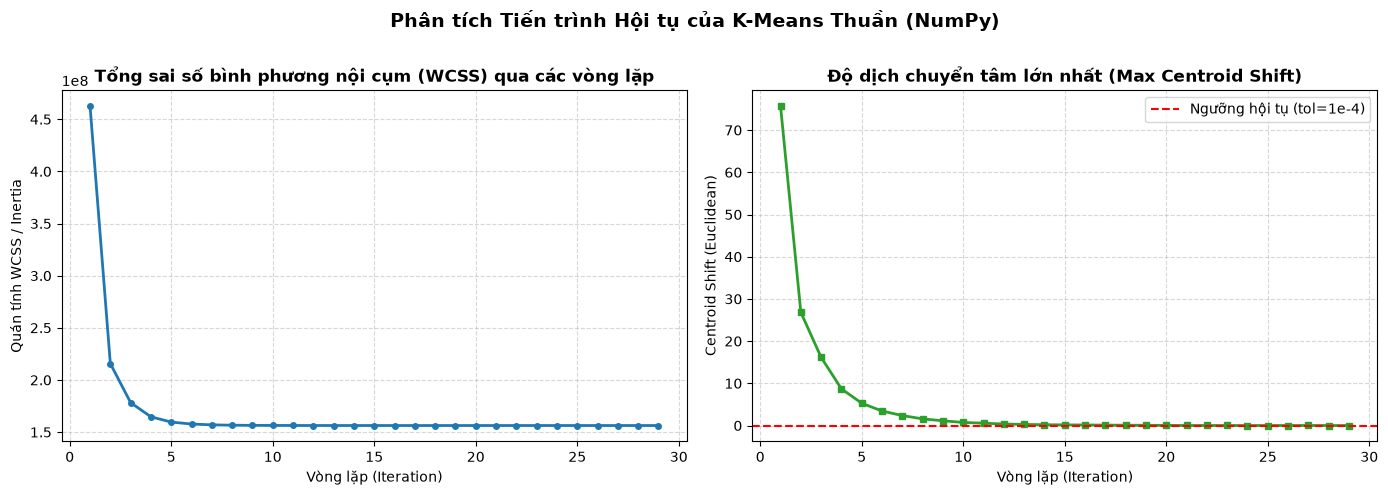

In [4]:
# Lưu đồ thị ra thư mục results/figures
plot_convergence_tracking(
    history_df,
    save_path=FIGURES_DIR / "kmeans_convergence_nb02.png"
)

# Hiển thị trực tiếp đồ thị tương tác trong notebook
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

iters = history_df["iteration"]

# Đồ thị WCSS
axes[0].plot(iters, history_df["inertia"], marker="o", markersize=4, color="#1f77b4", linewidth=2)
axes[0].set_title("Tổng sai số bình phương nội cụm (WCSS) qua các vòng lặp", fontweight="bold")
axes[0].set_xlabel("Vòng lặp (Iteration)")
axes[0].set_ylabel("Quán tính WCSS / Inertia")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Đồ thị Centroid Shift
axes[1].plot(iters, history_df["centroid_shift"], marker="s", markersize=4, color="#2ca02c", linewidth=2)
axes[1].axhline(y=1e-4, color="r", linestyle="--", label="Ngưỡng hội tụ (tol=1e-4)")
axes[1].set_title("Độ dịch chuyển tâm lớn nhất (Max Centroid Shift)", fontweight="bold")
axes[1].set_xlabel("Vòng lặp (Iteration)")
axes[1].set_ylabel("Centroid Shift (Euclidean)")
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend()

plt.suptitle("Phân tích Tiến trình Hội tụ của K-Means Thuần (NumPy)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 5. Đánh giá và nhận xét
1. **Tính chất đơn điệu của hàm mục tiêu**: Quán tính WCSS giảm liên tục qua từng vòng lặp, minh chứng thuật toán tính toán đúng theo nguyên lý tối thiểu hóa hàm mất mát của K-Means.
2. **Tốc độ hội tụ**: Thuật toán đạt điều kiện dừng sớm sau một số lượng vòng lặp hữu hạn, độ dịch chuyển tâm nhanh chóng tiệm cận về 0.
3. Thuật toán tự viết đã hoạt động ổn định và sẵn sàng đối chiếu với thư viện Scikit-Learn ở Notebook 03.